# Tugas 3 — Segmentasi Pelanggan (*Clustering*)

Notebook ini menjalankan pipeline Tugas 3 langkah demi langkah dengan kode yang sama seperti
`python kode/run_all.py --stages clustering`. Setiap butir menjalankan modulnya di
`kode/src/clustering/`, lalu menampilkan ringkasan angka dari `kode/results/` dan grafik dari
`kode/figures/`.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 3a | Prapemrosesan dan deteksi awal akun bot | `preprocess.py` | Firdaus Arif Ramadhani |
| 3b | Seleksi fitur dan pembobotan blok | `features.py` | Firdaus Arif Ramadhani |
| 3c | Perbandingan metode *clustering* | `models.py` | Rainaldi Pakpahan |
| 3d | Pemilihan jumlah klaster K | `models.py` | Rainaldi Pakpahan |
| 3e | Stabilitas lewat *subsampling* | `stability.py` | Rainaldi Pakpahan |
| 3f | Profil segmen dan aksi pemasaran | `analysis.py` | Rainaldi Pakpahan |
| 3g | Anomali (`cluster = -1`) dan `cluster.csv` | `analysis.py` | Rainaldi Pakpahan |

Penilaian memakai ARI terhadap segmen acuan tersembunyi; label `-1` menandai anomali.
Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan dua pembantu: `baca_hasil()` untuk membaca JSON hasil
dan `tampilkan_gambar()` untuk menampilkan grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama: str, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    gambar = PILImage.open(FIGURES_DIR / nama)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 3a. Prapemrosesan

*Penanggung jawab: Firdaus Arif Ramadhani*

1. **Deteksi awal akun bot** sebelum penskalaan: GMM 2 komponen pada empat indikator aktivitas
   (`sesi_per_minggu`, `durasi_sesi_menit`, `klik_iklan_30h`, `wishlist`), agar nilai ekstrem bot tidak
   mengganggu skala, imputasi, dan sentroid.
2. **Transformasi sesuai jenis variabel:** `log` setelah *winsorizing* untuk variabel positif yang
   menceng, `log1p` untuk variabel cacah, `logit` untuk proporsi, standardisasi untuk `umur`.
3. **Imputasi `rata2_keranjang`** yang kosong (seluruhnya pelanggan dengan `frekuensi_90h = 0`) memakai
   Ridge pada skala log.
4. **Data komposisional** (`porsi_<kategori>` dan `porsi_jam_*`) diubah dengan *centered log-ratio* (CLR).
5. **Kategori:** `perangkat` menjadi indikator `is_ios`; `kota_tier` tidak membawa sinyal.

In [2]:
%run ../src/clustering/preprocess.py --save-json

[START] Task 3a: Preprocessing & Data Quality Audit


Dataset       : 120,000 baris x 60 kolom (anomali bot pra-skala: 1,800 = 1.50%)
Nilai hilang  : rata2_keranjang=6,647 (5.62% non-bot, 100% frekuensi_90h==0), Ridge R^2=0.3266
Jurang nol    : naif max kemurnian f0=100.0% (konsentrasi 100.0%) -> kanonik=21.5% (ARI naif vs kanonik=0.6527)
Kategorikal   : kota_tier Kruskal p=0.2478 (noise), perangkat p=0.00e+00, android vs web p=0.2690
Figur         : task3_3a_preprocessing.png
[DONE]  Task 3a: Preprocessing & Data Quality Audit (9.35s)


**Deteksi awal akun bot**

,nilai
n_total,120000
n_bot,1800
n_normal,118200
pct_bot,1.5
bot_min_posterior,1.0
normal_max_posterior,0.0


**Kemencengan (*skewness*) sebelum dan sesudah transformasi**

,sebelum,sesudah
frekuensi_90h,3.5352,-0.1892
item_per_pesanan,3.4840,0.7579
lama_member_bulan,3.2717,-0.5220
persen_cod,0.7847,0.0734
persen_flash_sale,0.3571,0.0832
persen_paylater,1.3200,0.6344
persen_voucher,-0.0088,0.0350
rata2_keranjang,3.5683,0.2924
recency_hari,7.9554,0.5846
retur_90h,2.8214,0.8124


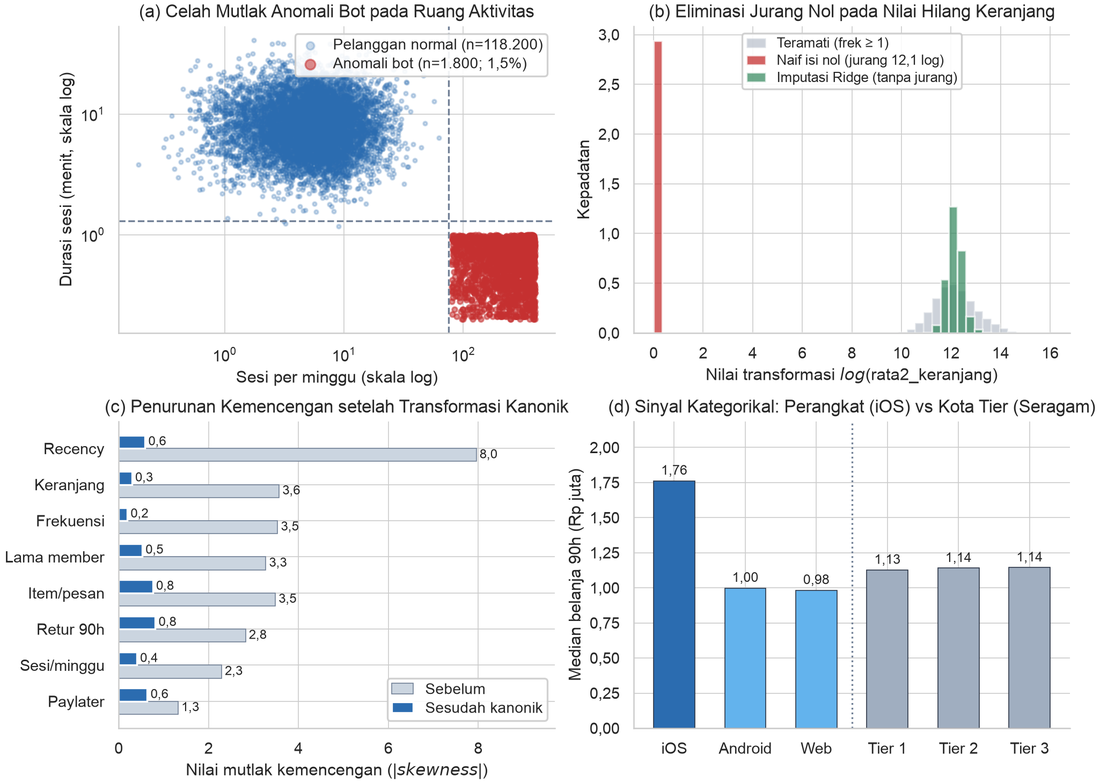

In [3]:
pra = baca_hasil("task3_preprocess.json")
bot = pra["bot_prescreening"]
display(Markdown("**Deteksi awal akun bot**"))
display(pd.Series({k: bot[k] for k in ("n_total", "n_bot", "n_normal", "pct_bot",
                                         "bot_min_posterior", "normal_max_posterior")},
                  name="nilai", dtype=object).to_frame())
display(Markdown("**Kemencengan (*skewness*) sebelum dan sesudah transformasi**"))
transformasi = pra["canonical_transform"]
display(pd.DataFrame({"sebelum": transformasi["skew_before"], "sesudah": transformasi["skew_after"]}))
tampilkan_gambar("task3_3a_preprocessing.png")

## 3b. Seleksi Fitur dan Pembobotan Blok

*Penanggung jawab: Firdaus Arif Ramadhani*

Seluruh 59 fitur kandidat disaring pada pelanggan non-bot dengan tiga bukti independen: koherensi
multivariat Spearman, prediktabilitas silang *out-of-fold* (Ridge R²), dan koefisien bimodalitas Sarle.
Fitur *noise*, redundan, dan kategori berprofil datar dibuang; fitur terpilih diberi bobot per blok
(perilaku inti, CLR waktu belanja, `is_ios`, CLR kategori). Ablasi lima konfigurasi pada K = 6
membuktikan dampaknya.

In [4]:
%run ../src/clustering/features.py --run-ablation --save-json

[START] Task 3b: Feature Selection & Block Weighting


Figur         : task3_3b_feature_selection.png
Seleksi fitur : 59 kandidat -> 26D terbobot -> PCA-12 (varians kumulatif 80.5%)
Pangsa varians blok 26D: {'core_behavior_13': 71.9, 'time_clr_3': 16.6, 'device_ios_1': 1.4, 'category_clr_9': 10.1}
Ablasi K=6:
  all_59_raw               (61D): KM_sil=0.0484, GMM_sil=0.0036, KM-GMM_ARI=0.3291, GMM_stab=0.2792
  drop_n15_only            (46D): KM_sil=0.0528, GMM_sil=0.0414, KM-GMM_ARI=0.2466, GMM_stab=0.4151
  selected_26d_unweighted  (26D): KM_sil=0.0896, GMM_sil=0.0761, KM-GMM_ARI=0.7658, GMM_stab=0.8162
  selected_26d_weighted    (26D): KM_sil=0.1125, GMM_sil=0.1095, KM-GMM_ARI=0.8339, GMM_stab=0.9995
  selected_pca12           (12D): KM_sil=0.1470, GMM_sil=0.1448, KM-GMM_ARI=0.8482, GMM_stab=0.9996
[DONE]  Task 3b: Feature Selection & Block Weighting (47.98s)


**Status setiap kelompok fitur**

,count,max_spearman_sum_r2,max_oof_r2,max_sarle_bimodality,features
dropped_anonymous_noise,15,0.0016,0.0000,0.6834,"n01, n02, n03, n04, n05, n06, n07, n08, n09, n..."
dropped_bot_only_detector,3,0.0010,0.0000,0.5318,"durasi_sesi_menit, wishlist, klik_iklan_30h"
dropped_low_signal_category,7,0.0146,0.0057,0.5954,"porsi_olahraga, porsi_otomotif, porsi_kesehata..."
dropped_named_noise,3,0.0012,0.0000,0.6571,"rating_beri_rata2, kota_tier, jumlah_alamat"
dropped_redundant,4,1.9601,0.9563,0.4892,"belanja_90h, rasio_konversi, belanja_30h, frek..."
selected_category_clr,9,0.2503,0.1033,0.6125,"porsi_fashion, porsi_makanan_minuman, porsi_ke..."
selected_core_behavior,13,0.8946,0.5801,0.7187,"frekuensi_90h, ulasan_90h, persen_voucher, per..."
selected_device_ios,1,0.1908,0.0965,1.0000,perangkat
selected_time_clr,4,0.4304,0.1785,0.5374,"porsi_jam_malam, porsi_jam_pagi, porsi_jam_sia..."


**Ablasi konfigurasi fitur pada K = 6**

,gmm_mean_max_posterior,gmm_seed_stability_ari,gmm_silhouette,km_calinski_harabasz,km_davies_bouldin,km_gmm_agreement_ari,km_seed_stability_ari,km_silhouette,n_dims
all_59_raw,0.9519,0.2792,0.0036,945.9869,3.6267,0.3291,0.9983,0.0484,61
drop_n15_only,0.9647,0.4151,0.0414,1294.6203,3.3043,0.2466,0.7180,0.0528,46
selected_26d_unweighted,0.9218,0.8162,0.0761,1940.9487,2.7269,0.7658,0.9994,0.0896,26
selected_26d_weighted,0.9505,0.9995,0.1095,2742.1139,2.3561,0.8339,0.9987,0.1125,26
selected_pca12,0.9354,0.9996,0.1448,3803.8437,1.9856,0.8482,0.9984,0.1470,12


Bobot blok: {'category_clr_top9': 0.45, 'core_behavior': 1.0, 'device_ios': 0.5, 'time_clr': 1.0}


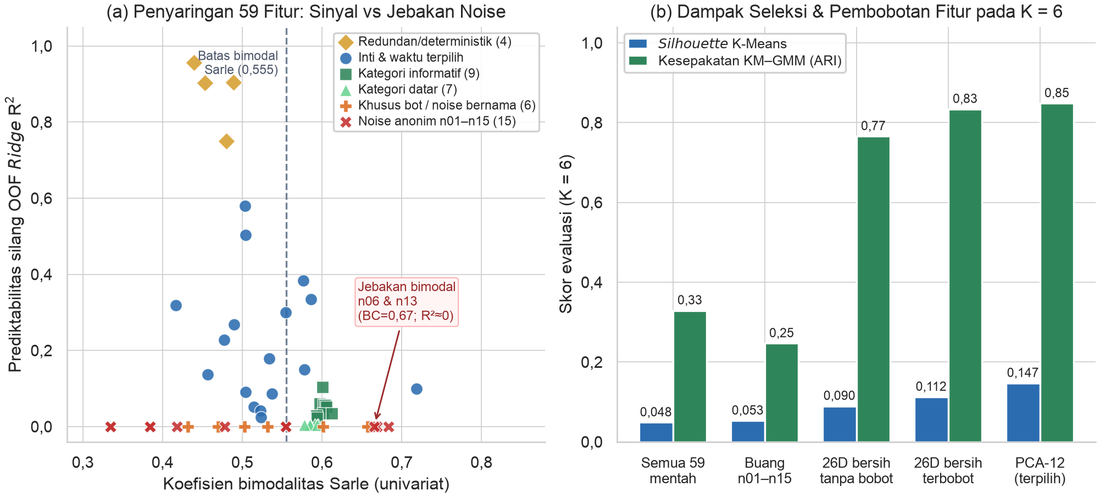

In [5]:
fitur = baca_hasil("task3_features.json")
status = pd.DataFrame.from_dict(fitur["status_summary"], orient="index")
status["features"] = status["features"].map(", ".join)
display(Markdown("**Status setiap kelompok fitur**"))
display(status[["count", "max_spearman_sum_r2", "max_oof_r2", "max_sarle_bimodality", "features"]])
display(Markdown("**Ablasi konfigurasi fitur pada K = 6**"))
display(tabel_metrik(fitur["ablation_k6"]).drop(columns=["gmm_sizes_pct"], errors="ignore"))
print("Bobot blok:", fitur["block_weights"])
tampilkan_gambar("task3_3b_feature_selection.png")